### Section 4: Measures of Shape and Distribution Geometry
#### Skewness, Kurtosis, Statistical Moments & Geometric Transformations

While **central tendency** gives the center (1st moment), and **dispersion** gives the spread (2nd moment), **measures of shape** describe the geometry of the distribution:
> **"Is the distribution lopsided (Skewness)? Are extreme outlier tails heavy or light (Kurtosis)?"**

Below are clear, naive examples covering the core measures of shape and geometry, complete with mathematical formulas, notation pronunciations, and Python implementation comparisons across **Plain Python**, **NumPy**, **SciPy**, and **Matplotlib**:
1. **The Four Statistical Moments**
2. **Skewness (Symmetric, Right-Skewed, Left-Skewed)**
3. **Pearson's & Bowley's Skewness Formulas**
4. **Kurtosis (Tail-Weight & Peakedness: Leptokurtic, Mesokurtic, Platykurtic)**
5. **Excess Kurtosis & Black Swan Risk**
6. **Fixing Skewness (Log & Power Transformations)**
7. **Summary Cheat Sheet & Decision Matrix**
---
---


### Setup


In [2]:
import statistics
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import math

# Set plot style
plt.style.use('seaborn_v0_8_white' if 'seaborn_v0_8_white' in plt.style.available else 'default')
plt.rcParams["figure.dpi"] = 100
np.random.seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. The Four Statistical Moments of a Distribution

Every distribution's geometry can be mathematically described by **four fundamental moments**:

| Moment | Name | Mathematical Formula | What it Describes |
| :---: | :---: | :---: | :--- |
| **1st Moment** | **Mean ($\mu$)** | $\frac{1}{n}\sum x_i$ | **Location / Center:** Center of mass of data |
| **2nd Moment** | **Variance ($\sigma^2$)** | $\frac{1}{n}\sum (x_i - \mu)^2$ | **Scale / Dispersion:** Spread around the center |
| **3rd Moment** | **Skewness ($g_1$)** | $\frac{1}{n\sigma^3}\sum (x_i - \mu)^3$ | **Asymmetry / Shape:** Left vs. Right tail stretch |
| **4th Moment** | **Kurtosis ($a_4$)** | $\frac{1}{n\sigma^4}\sum (x_i - \mu)^4$ | **Tails / Extremes:** Propensity for extreme outlier events |


---
## 2. Skewness (Asymmetry of the Distribution)

* **What it does:** Measures the degree and direction of asymmetry in a distribution.
* **Three Fundamental Shapes:**
  1. **Symmetric (Normal / Bell Curve, $\text{Skew} \approx 0$):**
     * Both tails are balanced.
     * $\mathbf{\text{Mean} \approx \text{Median} \approx \text{Mode}}$
  2. **Positively Skewed (Right-Skewed, $\text{Skew} > 0$):**
     * The long tail stretches to the **right** (positive direction).
     * High outlier values pull the mean: $\mathbf{\text{Mean} > \text{Median} > \text{Mode}}$
     * *Examples:* Household income, house prices, software bug fix times.
  3. **Negatively Skewed (Left-Skewed, $\text{Skew} < 0$):**
     * The long tail stretches to the **left** (negative direction).
     * Low outlier values pull the mean down: $\mathbf{\text{Mean} < \text{Median} < \text{Mode}}$
     * *Examples:* Age at natural death in developed nations, scores on an easy exam.


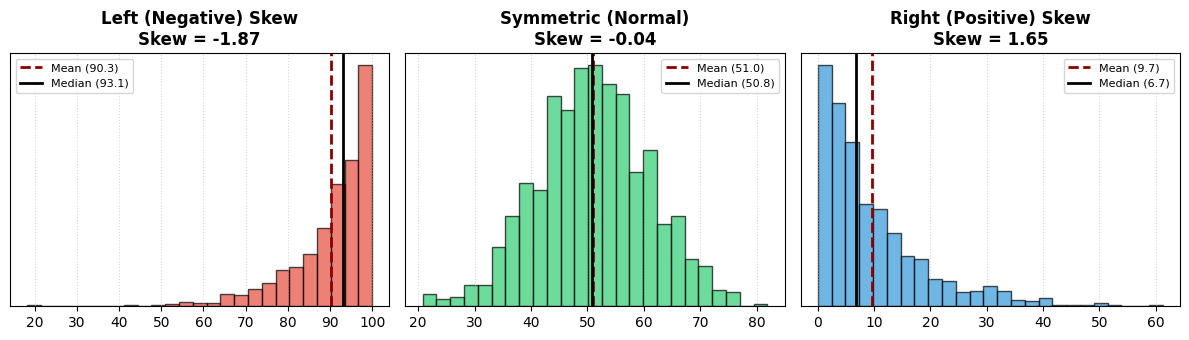

In [5]:
# 2. Skewness Visual Demonstration
np.random.seed(42)

# Generate 3 representative datasets
n = 1000
left_skewed  = 100 - np.random.exponential(scale=10, size=n)   # Negative skew
symmetric    = np.random.normal(loc=50, scale=10, size=n)       # Zero skew
right_skewed = np.random.exponential(scale=10, size=n)          # Positive skew

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=False)

datasets = [left_skewed, symmetric, right_skewed]
titles = [f"Left (Negative) Skew\nSkew = {stats.skew(left_skewed):.2f}", 
          f"Symmetric (Normal)\nSkew = {stats.skew(symmetric):.2f}", 
          f"Right (Positive) Skew\nSkew = {stats.skew(right_skewed):.2f}"]
colors = ['#e74c3c', '#2ecc71', '#3498db']

for ax, d, t, c in zip(axes, datasets, titles, colors):
    ax.hist(d, bins=25, color=c, alpha=0.7, density=True, edgecolor='black')
    
    # Mark Mean and Median
    mean_val = np.mean(d)
    med_val  = np.median(d)
    ax.axvline(mean_val, color='darkred', linestyle='--', lw=2, label=f'Mean ({mean_val:.1f})')
    ax.axvline(med_val,  color='black',   linestyle='-',  lw=2, label=f'Median ({med_val:.1f})')
    
    ax.set_title(t, fontweight='bold')
    ax.set_yticks([])
    ax.legend(fontsize=8)
    ax.grid(axis='x', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 3. Calculating Skewness in Python

### A. Pearson's Median Skewness (Simple / Intuitive):
$$Sk_2 = \frac{3(\bar{x} - \text{Median})}{s}$$
* If $\bar{x} > \text{Median} \implies$ Positive Skew
* If $\bar{x} < \text{Median} \implies$ Negative Skew

### B. Fisher-Pearson Standardized Moment (SciPy Default):
$$g_1 = \frac{\frac{1}{n} \sum (x_i - \bar{x})^3}{s^3}$$

### C. Bowley's Quartile Skewness (Robust against Outliers):
$$Sk_B = \frac{(Q_3 - Q_2) - (Q_2 - Q_1)}{Q_3 - Q_1} = \frac{Q_3 + Q_1 - 2Q_2}{Q_3 - Q_1}$$
* Bounded strictly between $-1.0$ and $+1.0$.


In [7]:
# 3. Skewness Formulas Example: Daily Household Incomes (₹ Thousands)
incomes = [15, 18, 20, 22, 25, 28, 30, 35, 120]  # Outlier of 120 creates right skew

mean_inc = np.mean(incomes)
med_inc  = np.median(incomes)
std_inc  = np.std(incomes, ddof=1)
n = len(incomes)

# 1. Pearson's Median Skewness
pearson_skew = 3 * (mean_inc - med_inc) / std_inc

# 2. Fisher-Pearson 3rd Moment (Plain Python)
m3 = sum((x - mean_inc)**3 for x in incomes) / n
m2 = sum((x - mean_inc)**2 for x in incomes) / n
fisher_skew_python = m3 / (m2 ** 1.5)

# 3. SciPy stats.skew (bias=False for sample-unbiased)
fisher_skew_scipy = stats.skew(incomes, bias=False)

# 4. Bowley's Quartile Skewness
q1, q2, q3 = np.percentile(incomes, [25, 50, 75])
bowley_skew = (q3 + q1 - 2*q2) / (q3 - q1)

print(f"Data: {incomes}")
print(f"Mean   : ₹{mean_inc:.1f}k | Median : ₹{med_inc:.1f}k")
print("-" * 55)
print(f"Pearson's Median Skewness     : {pearson_skew:+.3f}")
print(f"Fisher-Pearson Skew (Python)  : {fisher_skew_python:+.3f}")
print(f"Fisher-Pearson Skew (SciPy)   : {fisher_skew_scipy:+.3f}")
print(f"Bowley's Quartile Skewness    : {bowley_skew:+.3f}")
print("-" * 55)
print("Conclusion: Positive value confirms Right-Skewed distribution!")


Data: [15, 18, 20, 22, 25, 28, 30, 35, 120]
Mean   : ₹34.8k | Median : ₹25.0k
-------------------------------------------------------
Pearson's Median Skewness     : +0.901
Fisher-Pearson Skew (Python)  : +2.304
Fisher-Pearson Skew (SciPy)   : +2.793
Bowley's Quartile Skewness    : +0.000
-------------------------------------------------------
Conclusion: Positive value confirms Right-Skewed distribution!


---
## 4. Kurtosis (Tail-Weight & Extreme Event Risk)

* **What it does:** Measures **tail-heaviness** and outlier propensity (NOT just peakedness!).
* **Three Categories of Kurtosis:**
  1. **Mesokurtic (Kurtosis $\approx 3$, Excess Kurtosis $\approx 0$):**
     * Normal bell curve. Standard baseline tail risk.
  2. **Leptokurtic (Kurtosis $> 3$, Excess Kurtosis $> 0$):**
     * *"Lepto"* = slender / fat tails.
     * Sharp peak with **heavy, fat tails**. High probability of extreme outlier events ("Black Swans").
     * *Example:* Stock market daily returns, crypto price shocks.
  3. **Platykurtic (Kurtosis $< 3$, Excess Kurtosis $< 0$):**
     * *"Platy"* = broad / flat (like a platypus bill).
     * Flat top and **thin, short tails**. Very low probability of extreme outliers.
     * *Example:* Uniform distribution, dice roll outcomes.

---

### Full Kurtosis vs. Excess Kurtosis:
$$\text{Full Kurtosis } (\beta_2) = \frac{\frac{1}{n} \sum (x_i - \bar{x})^4}{s^4}$$
$$\mathbf{\text{Excess Kurtosis}} = \beta_2 - 3$$
*(SciPy and Pandas report **Excess Kurtosis** so that Normal Distribution = 0.0)*


<string>:11: RuntimeWarning: invalid value encountered in sqrt


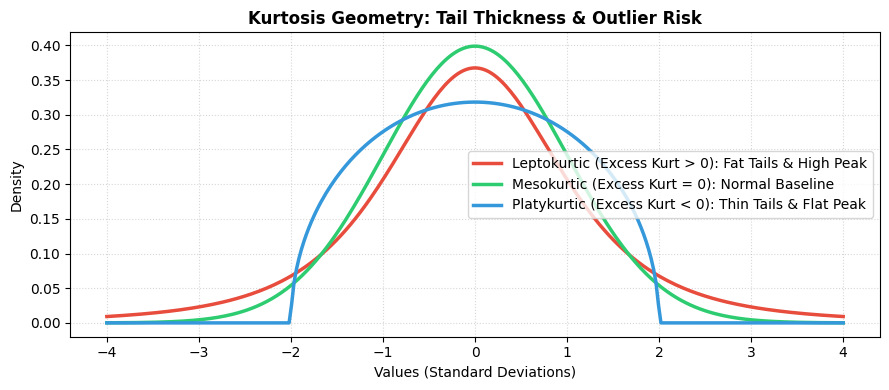

In [9]:
# 4. Kurtosis Visual Comparison
x_vals = np.linspace(-4, 4, 300)

# 1. Leptokurtic: Student-t distribution (df=3 has heavy tails)
lepto_pdf = stats.t.pdf(x_vals, df=3)

# 2. Mesokurtic: Standard Normal distribution
meso_pdf = stats.norm.pdf(x_vals, 0, 1)

# 3. Platykurtic: Wigner Semicircle / Flat curve
platy_pdf = np.where(np.abs(x_vals) <= 2, 2 / (np.pi * 4) * np.sqrt(4 - x_vals**2), 0)

plt.figure(figsize=(9, 4))
plt.plot(x_vals, lepto_pdf, color='#e74c3c', lw=2.5, label='Leptokurtic (Excess Kurt > 0): Fat Tails & High Peak')
plt.plot(x_vals, meso_pdf,  color='#2ecc71', lw=2.5, label='Mesokurtic (Excess Kurt = 0): Normal Baseline')
plt.plot(x_vals, platy_pdf, color='#3498db', lw=2.5, label='Platykurtic (Excess Kurt < 0): Thin Tails & Flat Peak')

plt.title('Kurtosis Geometry: Tail Thickness & Outlier Risk', fontweight='bold')
plt.xlabel('Values (Standard Deviations)')
plt.ylabel('Density')
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


---
## 5. Calculating Kurtosis in Python


In [11]:
# 5. Kurtosis Example: Normal vs. Volatile Stock Returns
stock_stable = [0.2, -0.1, 0.3, 0.1, -0.2, 0.0, 0.1, -0.1, 0.2, 0.0]
stock_crypto = [0.1, -0.2, 0.1, 0.0, -0.1, 0.2, 0.1, -0.1, 8.5, -9.2]  # Extreme spikes!

# SciPy stats.kurtosis (fisher=True gives Excess Kurtosis, fisher=False gives Full Kurtosis)
excess_kurt_stable = stats.kurtosis(stock_stable, fisher=True, bias=False)
full_kurt_stable   = stats.kurtosis(stock_stable, fisher=False, bias=False)

excess_kurt_crypto = stats.kurtosis(stock_crypto, fisher=True, bias=False)
full_kurt_crypto   = stats.kurtosis(stock_crypto, fisher=False, bias=False)

print(f"{'Asset':<18} | {'Full Kurtosis (β2)':<20} | {'Excess Kurtosis (β2 - 3)':<24} | {'Tail Nature'}")
print("-" * 75)
print(f"{'Stable Stock':<18} | {full_kurt_stable:<20.2f} | {excess_kurt_stable:<24.2f} | Platykurtic / Normal")
print(f"{'Crypto / Volatile':<18} | {full_kurt_crypto:<20.2f} | {excess_kurt_crypto:<24.2f} | Leptokurtic (Heavy Tails!)")
print("-" * 75)


Asset              | Full Kurtosis (β2)   | Excess Kurtosis (β2 - 3) | Tail Nature
---------------------------------------------------------------------------
Stable Stock       | 2.10                 | -0.90                    | Platykurtic / Normal
Crypto / Volatile  | 7.52                 | 4.52                     | Leptokurtic (Heavy Tails!)
---------------------------------------------------------------------------


---
## 6. Fixing Skewness: Data Transformations

* **Why fix skewness?**
  * Many machine learning models (Linear Regression, Logistic Regression, PCA) perform best when features are approximately normally distributed.
* **Common Remedies for Right-Skewed Data:**
  1. **Log Transformation:** $y = \log(x)$ or $y = \log(1 + x)$ (compresses large right-hand outliers).
  2. **Square Root Transformation:** $y = \sqrt{x}$ (mild right skew).
  3. **Box-Cox Power Transformation:** Finds the mathematically optimal power parameter $\lambda$.


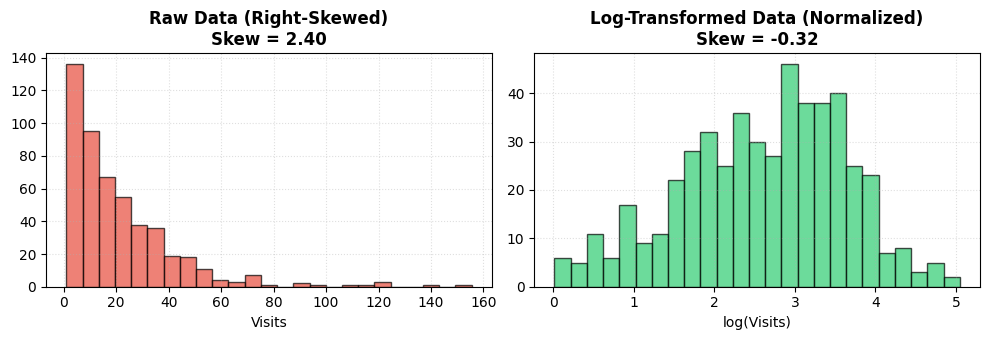

In [13]:
# 6. Fixing Right-Skewed Data using Log Transformation
# Heavily skewed positive values (e.g. Website page visits)
raw_visits = np.random.exponential(scale=20, size=500) + 1

# Log transform
log_visits = np.log(raw_visits)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

# Raw Data
ax1.hist(raw_visits, bins=25, color='#e74c3c', alpha=0.7, edgecolor='black')
ax1.set_title(f'Raw Data (Right-Skewed)\nSkew = {stats.skew(raw_visits):.2f}', fontweight='bold')
ax1.set_xlabel('Visits')
ax1.grid(True, linestyle=':', alpha=0.4)

# Log Transformed
ax2.hist(log_visits, bins=25, color='#2ecc71', alpha=0.7, edgecolor='black')
ax2.set_title(f'Log-Transformed Data (Normalized)\nSkew = {stats.skew(log_visits):.2f}', fontweight='bold')
ax2.set_xlabel('log(Visits)')
ax2.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()


---
## 7. Master Cheat Sheet & Decision Matrix

| Metric | Range / Threshold | Interpretation | Action / Decision |
| :--- | :--- | :--- | :--- |
| **Skewness** | $-0.5 \le \text{Skew} \le +0.5$ | **Fairly Symmetric** | Mean and Standard Deviation are safe to use. |
| **Skewness** | $+0.5 < \text{Skew} \le +1.0$ | **Moderately Skewed** | Prefer Median / IQR; consider square-root transform. |
| **Skewness** | $\text{Skew} > +1.0$ or $\text{Skew} < -1.0$ | **Highly Skewed** | Mean is distorted! Use Log / Box-Cox transform. |
| **Excess Kurtosis** | $\text{Kurt} \approx 0$ | **Mesokurtic (Normal)** | Standard Gaussian assumption holds. |
| **Excess Kurtosis** | $\text{Kurt} > 0$ | **Leptokurtic (Fat Tails)** | High risk of extreme outlier events; use robust metrics. |
| **Excess Kurtosis** | $\text{Kurt} < 0$ | **Platykurtic (Thin Tails)** | Few outliers; safe predictable bounds. |
